### Session 0 load depandancies and environmental variables

In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
## a useful function to generate a data list for further analysis
import os,json,sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from scipy.io import savemat
from analyse_stimulus_evoked_response import main,plotting_visual_guided_response
##need to add this additional cell because useful tools are in another folder. Need to integrate these two folders one day
current_working_directory = Path.cwd()
parent_dir = current_working_directory.resolve().parents[0]
sys.path.insert(0, str(parent_dir) + "\\utilities")
from useful_tools import select_animals_gpt, find_file,get_fill_between_range,column_name_list
from data_cleaning import preprocess_fictrac_data,update_csv_value_pd
sys.path.insert(0, str(parent_dir) + "\\UnityDataAnalysis")
from trajectory_analysis import plot_scatter_violin

Transition indices: [2 4 7]


In [3]:
##introduce some helper class to define colour gradient
import matplotlib as mpl
from matplotlib import cm
class MplColorHelper:
    def __init__(self, cmap_name, start_val, stop_val):
        self.cmap_name = cmap_name
        self.cmap = plt.get_cmap(cmap_name)
        self.norm = mpl.colors.Normalize(vmin=start_val, vmax=stop_val)
        self.scalarMap = cm.ScalarMappable(norm=self.norm, cmap=self.cmap)

    def get_rgb(self, val):
        return self.scalarMap.to_rgba(val)
#colormap_name = "viridis"
colormap_name = "coolwarm"
# COL = MplColorHelper(colormap_name, 0, len(df["stim_type"].unique()))
# sm = cm.ScalarMappable(cmap=colormap_name)

#### Session 0.1: Load analysis methods in python dictionary form

In [4]:
#sheet_name="MatrexVR"
#sheet_name="VCCball"
sheet_name="Zball"
json_file = "./analysis_methods_dictionary.json"
with open(json_file, "r") as f:
    analysis_methods = json.loads(f.read())

In [6]:
Datasets="Z:/DATA/experiment_trackball_Optomotor"
this_dataset_dir = f"{Datasets}/{sheet_name}"

#### calculate autocorrelation

In [ ]:
## this cell is used to do batch processing of calculating autocorrelation of the stimulus sequence
from pathlib import Path
from calculate_autocorrelation import load_data
sheet_name="random_3duration_3coherence"
json_file = "./analysis_methods_dictionary.json"
with open(json_file, "r") as f:
    analysis_methods = json.loads(f.read())
Datasets=r"Z:\Users\chiyu\random_seed_autocorrelation_analysis"
this_dataset_dir = f"{Datasets}/{sheet_name}"
file_type=".csv"
for this_file in os.listdir(this_dataset_dir):
    if this_file.endswith(file_type):
        load_data(Path(this_dataset_dir) / this_file,analysis_methods)

In [ ]:
def batch_calculate_stim_bias(dir_list,partial_analysis):
    ISI_ID_lag=np.zeros((len(dir_list),5))
    stim_ID_lag=np.zeros((len(dir_list),5))
    stim_type_lag=np.zeros((len(dir_list),5))
    stim_direction_arr=np.zeros((len(dir_list),2))
    ISI_type_arr=np.zeros((len(dir_list),2))
    stim_type_arr=np.zeros((len(dir_list),7))
    i=0
    for this_dir in dir_list:    
        trial_pattern = "trial*.csv"
        csv_file_directory = find_file(this_dir, trial_pattern)
        stim_direction,ISI_type,stim_type,lag_data=load_data(csv_file_directory, json_file, partial_analysis)
        stim_type_arr[i,:]=stim_type
        stim_direction_arr[i,:]=stim_direction
        ISI_type_arr[i,:]=ISI_type
        ISI_ID_lag[i,:]=lag_data[0,:]
        stim_ID_lag[i,:]=lag_data[1,:]
        stim_type_lag[i,:]=lag_data[2,:]
        i=i+1
    print(f'{stim_type_arr.sum(axis=0)}')
    print(f'{stim_direction_arr.sum(axis=0)}')
    print(f'{ISI_type_arr.sum(axis=0)}')
    print(f'{ISI_ID_lag.mean(axis=0)}')
    print(f'{stim_ID_lag.mean(axis=0)}')
    print(f'{stim_type_lag.mean(axis=0)}')

In [ ]:
batch_calculate_stim_bias(dir_list,'early')
batch_calculate_stim_bias(dir_list,'middle')
batch_calculate_stim_bias(dir_list,'late')
'''
early
[424. 479. 540. 643. 589. 769. 532.]
424+532=956
479+769=1248
[1443. 1890.]
[1845. 2131.]
[-0.04762321 -0.1164732   0.01016095 -0.03843581 -0.14988475]
[ 0.00915247 -0.12262615 -0.09840216 -0.03593258  0.04220985]
[-0.11599431 -0.06198225 -0.13341417 -0.03512159  0.08460859]
max is either around 0
middle
[610. 404. 620. 654. 499. 651. 538.]
610+538=1148
404+651=1055
[1634. 1688.]
[2005. 1971.]
[ 0.00699606 -0.0320632  -0.05037562  0.13221885 -0.1800306 ]
[-0.0411484   0.00134714  0.05059404 -0.06485119  0.03194663]
[ 0.02552978 -0.12638919 -0.17651796 -0.11105817 -0.0898633 ]
max is either around 0.1 or -0.2
late
[461. 628. 704. 560. 394. 667. 562.]
461+562=1023
628+667=1295
[1793. 1623.]
[1719. 2257.]
[-0.08652557  0.04749003 -0.11511646 -0.00731669  0.02468436]
[-0.1190309   0.06575864 -0.07625521  0.02529781  0.06616186]
[-0.10959492 -0.0464329   0.02816368 -0.04218896  0.03156868]
max is either around 0.1 or -0.2
'''

#### Session 0.2: Load animal directory as a list

In [5]:
## to load all directories with behavioural session including electrophysiology data
dir_list = []
# Datasets=[r"Y:\GN25051",r"Y:\GN25052",r"Y:\GN25053",r"Y:\GN25054",r"Y:\GN25055",r"Y:\GN25056",r"Y:\GN25057",r"Y:\GN25058",r"Y:\GN25059",r"Y:\GN25060",r"Y:\GN25061",
#           r"Y:\GN25062",r"Y:\GN25063",r"Y:\GN25064",r"Y:\GN25065",r"Y:\GN25066",r"Y:\GN25067",r"Y:\GN25068",r"Y:\GN25069",r"Y:\GN26008",r"Y:\GN26007"]
Datasets=[r"Y:\GN26011",r"Y:\GN26012"]
for thisDataset in Datasets:
    for root, dirs, files in os.walk(thisDataset):
        for folder in dirs:
            if folder.startswith("Record"):
                dir_interest=Path(root)
                dir_list.append(dir_interest.parent)

In [4]:
## to load one animal's all behavioural session in z ball (wihtout electrophysiology)
dir_list = []
file_type=".dat"
#Datasets=[r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26109",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26108",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26107",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26106"]
Datasets=[r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26110",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26111",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26112",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26113",
          r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26114",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26115",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26116",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26117",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26118"]
for thisDataset in Datasets:
    for root, dirs, files in os.walk(thisDataset):
        for folder in dirs:
            if folder.startswith("session"):
                folder_path=os.path.join(root,folder)
                if any(name.endswith(file_type) for name in os.listdir(folder_path)):
                    dir_list.append(folder_path.replace("\\", "/"))

In [7]:
## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the dat file in that folder.
## In this project, we usually have one dat file in that folder so there is no confusion
dir_list = []
file_type=".dat"
for root, dirs, files in os.walk(this_dataset_dir):
    if analysis_methods.get("experiment_name") in root.split(
        os.path.sep
    ):  ## add this condition to avoid data from other experiments
        for folder in dirs:
            if folder.startswith("session"):
                folder_path=os.path.join(root,folder)
                if any(name.endswith(file_type) for name in os.listdir(folder_path)):
                    dir_list.append(folder_path.replace("\\", "/"))
print(f"these directories are found {dir_list}")

these directories are found ['Z:/DATA/experiment_trackball_Optomotor/Zball/GN25104/251223/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26104/260120/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26105/260120/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26106/260126/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26107/260126/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26108/260127/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26109/260127/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26110/260202/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26111/260202/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26112/260203/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26113/260203/conflict/session1', 'Z:/DATA/experiment_trackball_Optomotor/Zball/GN26114/260209/conflict/session1',

In [ ]:
##if there is a need to update csv file, use this cell
for this_dir in dir_list:
    old_csv_pattern = "lux*.csv"
    old_csv_path = find_file(this_dir, old_csv_pattern)
    new_csv_pattern = "camera*.csv"
    new_csv_path = find_file(this_dir, new_csv_pattern)
    print(f"old_csv_path: {old_csv_path}")
    update_csv_value_pd(old_csv_path,new_csv_path,0)

### Session 1.0: Create curated dataset based on the list of directories

In [ ]:
pattern="database*.pickle"
for this_dir in dir_list:
    if any(Path(this_dir).glob(pattern)) and analysis_methods.get("overwrite_curated_dataset")==False:
        print(f"curated fictrac data found in {this_dir}. Skip this file")
        continue
    else:
        print(f"no curated fictrac data in {this_dir} or overwrite option is selected. Create curated file")
        preprocess_fictrac_data(this_dir,analysis_methods)

In [ ]:
# Define the path to your Excel file
dir_list = []
# choose folders that contains fictrac .dat file
file_type=".dat"
using_google_sheet=True
experiment_name=analysis_methods.get("experiment_name")
if analysis_methods.get("load_experiment_condition_from_database") == True:
    if using_google_sheet==True:
        database_id = "1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8"
                #https://docs.google.com/spreadsheets/d/1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8/edit?usp=sharing
        url = f"https://docs.google.com/spreadsheets/d/{database_id}/gviz/tq?tqx=out:csv&sheet={sheet_name}"
        #df = pd.read_excel(url, engine='openpyxl')## use this function if the file is not google sheet but uploaded excel file

        df = pd.read_csv(url)
    else:
        excel_file_path = "Z:/DATA/experiment_trackball_Optomotor/Locusts Management.xlsx"
        print(f"using a database {excel_file_path} from the server but this file might be outdated")
        # Create a 'with' statement to open and read the Excel file
        with pd.ExcelFile(excel_file_path) as xls:
            # Read the Excel sheet into a DataFrame with the sheet name (folder name)
            df = pd.read_excel(xls, sheet_name)
        ##list up the conditions and answers as strings for input argument to select animal. One condition must pair with one answer
    if analysis_methods.get("select_animals_by_condition") == True:
        #animal_of_interest=select_animals_gpt(df,"Stimulus Type (list up all the stimulus paradigm this animal receive)","densities","Excluding this animal from analysis (Usually when animals die or molt, T/F)","F","Housing Condition before the experiment","solitarious")
        
        animal_of_interest=select_animals_gpt(df,"Independent variable1","conflict","Excluding this animal from analysis (Usually when animals die or molt, T/F)","F")
        #print(animal_of_interest)
    else:
        animal_of_interest=df

    ID_array=animal_of_interest["ID"].values
    #print(f"these are the ID of the animals {ID_array}")
    dir_list = [
    root.replace("\\", "/")
    for root, dirs, files in os.walk(this_dataset_dir)
    if any(ID in root for ID in ID_array)
    and experiment_name in root.split(os.path.sep)
    and any(name.endswith(file_type) for name in files)
]
else:
    ## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the hdf5 file in that folder.
    ## However,some changes need to be made once we do sleap or deeplabcut where there are more than one H5 file generated
    for root, dirs, files in os.walk(this_dataset_dir):
        if analysis_methods.get("experiment_name") in root.split(os.path.sep):## add this condition to avoid data from other experiments
            if any(name.endswith(file_type) for name in files):
                dir_list.append(root.replace("\\", "/"))

### Session 2.0: Analyse visually guided response

In [66]:
# locust loom sessions in ephys
#dir_list=[r"Y:\GN25051\251101\looming\session2",r"Y:\GN25053\251108\looming\session2",r"Y:\GN25053\251108\looming\session6",r"Y:\GN25058\251123\looming\session3",r"Y:\GN25060\251130\looming\session1",r"Y:\GN25061\251205\looming\session3"]
# loom 6 type 4 speed in ephys
#dir_list=[r"Y:\GN25061\251205\looming\session4",r"Y:\GN25060\251130\looming\session4",r"Y:\GN25059\251129\looming\session1",r"Y:\GN25058\251123\looming\session2",r"Y:\GN25057\251122\looming\session2", r"Y:\GN25053\251108\looming\session1",r"Y:\GN25052\251102\looming\session1", r"Y:\GN25051\251101\looming\session1"]
# loom 6 type 4 speed in ephys dark background thisDir = r"Y:\GN25053\251108\looming\session7"# walking session, also showing jumping epochs
# loom 6 type 4 speed sequential in ephys
#dir_list=[r"Y:\GN25053\251108\looming\session5",r"Y:\GN25060\251130\looming\session2", r"Y:\GN25062\251206\looming\session2",r"Y:\GN25061\251205\looming\session2"]
### sweeping conflict stimulus without ephys
dir_list=[r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26114\260209\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26115\260209\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26116\260210\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26117\260210\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26118\260210\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26113\260203\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26112\260203\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26111\260202\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26110\260202\sweeping\session2",
r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26107\260126\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26106\260126\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26109\260127\sweeping\session2"]
### sweeping rotation stimulus without ephys
# dir_list=[r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26114\260209\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26115\260209\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26116\260210\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26117\260210\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26118\260210\sweeping\session2",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26113\260203\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26112\260203\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26111\260202\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26110\260202\sweeping\session1",
# r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26107\260126\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26106\260126\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26108\260127\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26109\260127\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26104\260119\sweeping\session1",r"Z:\DATA\experiment_trackball_Optomotor\Zball\GN26105\260119\sweeping\session1"]

In [22]:
analysis_methods.update({'load_previous_methods':False})

In [ ]:
# because the import does not update the new version of python.
# Need to restart kernel 
summary_list=[]
output1_across_exp=[]
output2_across_exp=[]
output3_across_exp=[]
output4_across_exp=[]
for this_dir in dir_list[1:]:
    if "archive" in this_dir:
        print(f"skip archive folder for {this_dir}")
        continue
    else:
        summary,speed,rotation,travel_distance_whole_session=main(this_dir,analysis_methods)
        summary_list.append(summary)
        output1_across_exp.append(speed)
        output2_across_exp.append(rotation)
        output3_across_exp.append(travel_distance_whole_session)
        output4_across_exp.append(this_dir)

#### Session 2.1: add meta data

In [24]:
#If I ever want to add path and vid to every single row of the summary
from itertools import chain, repeat
#https://stackoverflow.com/questions/14878538/duplicate-elements-in-a-list
ll = list(chain.from_iterable(repeat(e, speed.shape[0]) for e in output4_across_exp))
camera_num=[]
video_pattern="camera*.mp4"
#final_list = list((lambda id: find_file(id,video_pattern).stem.split("_")[0], output4_across_exp))
for id in ll:
    found_result=find_file(id,video_pattern)
    camera_num.append(found_result.stem.split("_")[0])

In [25]:
df=pd.DataFrame(pd.concat(summary_list,axis=0, ignore_index=True))
new_data = {'Path': ll, 'VR_no': camera_num}
df = df.assign(**new_data)
growth_condition='g'
df.insert(0, 'growth_condition', np.repeat(growth_condition,summary_list[0].shape[0]*len(summary_list)).tolist())
df.insert(0, 'ID', np.repeat(np.arange(len(output4_across_exp)),summary_list[0].shape[0]).tolist())

#### Session 2.2 a particular cell for the conflict experiment

In [ ]:
## this is for conflict experiment where we have a single stimuli going different direction
df_rotation=np.concatenate(output2_across_exp)
colormap = np.array(["k", "r", "b", "g", "y", "m", "c", "k"])
y_axis_lim=[-0.5,0.5]
camera_fps = analysis_methods.get("camera_fps")
analysis_window=analysis_methods.get("analysis_window")
init_frame=abs(analysis_window[0])*camera_fps
fig, axes = plt.subplots(
    nrows=12, ncols=1, figsize=(18, 84), tight_layout=True
)
plot_count=0
c_angle_dependant_list1=[]
c_angle_dependant_list2=[]
c_angle_dependant_list3=[]
cc_angle_dependant_list1=[]
cc_angle_dependant_list2=[]
cc_angle_dependant_list3=[]
stim_duration=8
premature_turn=0.8
walk_threshold=1
for idx, this_stim in df.groupby(['R1','LocustTexture1','stim_type']):
    #print(this_stim)
    this_response=df_rotation[this_stim[(this_stim['travel_distance_isi']>walk_threshold)&(abs(this_stim['opto_index_isi'])<premature_turn)].index,:]
    #this_response=df_rotation[this_stim[this_stim['travel_distance_isi']>2.5].index,:]
    #this_response=df_rotation[this_stim.index,:]
    time_points = np.arange(this_response.shape[1])
    time_points_b = np.tile(time_points, (this_response.shape[0], 1))
    # idx.split("_")
    # if idx.endswith("fast"):
    #     stim_duration=8
    # elif idx.endswith("slow"):
    #     stim_duration=25
    # else:
    #     stim_duration=12
    axes[plot_count].plot(
        np.mean(time_points_b, axis=0),
        np.mean(this_response, axis=0),
        color='r',
        alpha=0.2,
    )
    axes[plot_count].axvline(
            x=init_frame,
            color="black",
            linestyle="--",
            label="Stimulus Starts",
        )
    axes[plot_count].axvline(
        x=init_frame + camera_fps * stim_duration,
        color="black",
        linestyle="--",
        label="Stimulus Ends",
    )
    axes[plot_count].set(
        yticks=[y_axis_lim[0], 0, y_axis_lim[1]],
        ylim=[y_axis_lim[0], y_axis_lim[1]],
        ylabel="Angular velocity (rad/s)",
        xlabel="Time (frames)",
        title=f'{idx}'
    )
    if idx[2].split("_")[0]=="cc" and idx[2].split("_")[1]=="back":
        print("this is a reverse translocated response")
        tmp=this_response[:,init_frame:init_frame+camera_fps * stim_duration]
        tmp_rev=tmp[:,::-1]
        angle_dependant_response=np.hstack((tmp_rev[:,int(tmp.shape[1]/2):],tmp_rev[:,:int(tmp.shape[1]/2)]))
    elif idx[2].split("_")[0]=="cc" and idx[2].split("_")[1]=="front":
        print("this is a reverse response")
        tmp=this_response[:,init_frame:init_frame+camera_fps * stim_duration]
        angle_dependant_response=tmp[:,::-1]
    elif idx[2].split("_")[0]=="c" and idx[2].split("_")[1]=="back":
        print("this is a translocated response")
        tmp=this_response[:,init_frame:init_frame+camera_fps * stim_duration]
        angle_dependant_response=np.hstack((tmp[:,int(tmp.shape[1]/2):],tmp[:,:int(tmp.shape[1]/2)]))
    else:
        print("this is a normal response")
        angle_dependant_response=this_response[:,init_frame:init_frame+camera_fps * stim_duration]
    if 'R1' in df.columns:
        if idx[1]==1 and idx[2].split("_")[0]=="cc":
            print(f"list 1 comes from locust texture {idx[1]}")
            cc_angle_dependant_list1.append(angle_dependant_response)
        elif idx[1]==0 and idx[0]==0 and idx[2].split("_")[0]=="cc":
            print(f"list 2 comes from locust texture {idx[1]} and colour{idx[0]}")
            cc_angle_dependant_list2.append(angle_dependant_response)
        elif idx[1]==0 and idx[0]!=0 and idx[2].split("_")[0]=="cc":
            print(f"list 3 comes from locust texture {idx[1]} and colour{idx[0]}")
            cc_angle_dependant_list3.append(angle_dependant_response)
        elif idx[1]==1 and idx[2].split("_")[0]=="c":
            c_angle_dependant_list1.append(angle_dependant_response)
        elif idx[1]==0 and idx[0]==0 and idx[2].split("_")[0]=="c":
            c_angle_dependant_list2.append(angle_dependant_response)
        elif idx[1]==0 and idx[0]!=0 and idx[2].split("_")[0]=="c":
            c_angle_dependant_list3.append(angle_dependant_response)
    else:
        if stim_duration==8 and idx[2].split("_")[0]=="cc":
            cc_angle_dependant_list1.append(angle_dependant_response)
        elif stim_duration==12 and idx[2].split("_")[0]=="cc":
            cc_angle_dependant_list2.append(angle_dependant_response)
        elif stim_duration==25 and idx[2].split("_")[0]=="cc":
            cc_angle_dependant_list3.append(angle_dependant_response)
        elif stim_duration==8 and idx[2].split("_")[0]=="c":
            c_angle_dependant_list1.append(angle_dependant_response)
        elif stim_duration==12 and idx[2].split("_")[0]=="c":
            c_angle_dependant_list2.append(angle_dependant_response)
        elif stim_duration==25 and idx[2].split("_")[0]=="c":
            c_angle_dependant_list3.append(angle_dependant_response)
    plot_count=plot_count+1

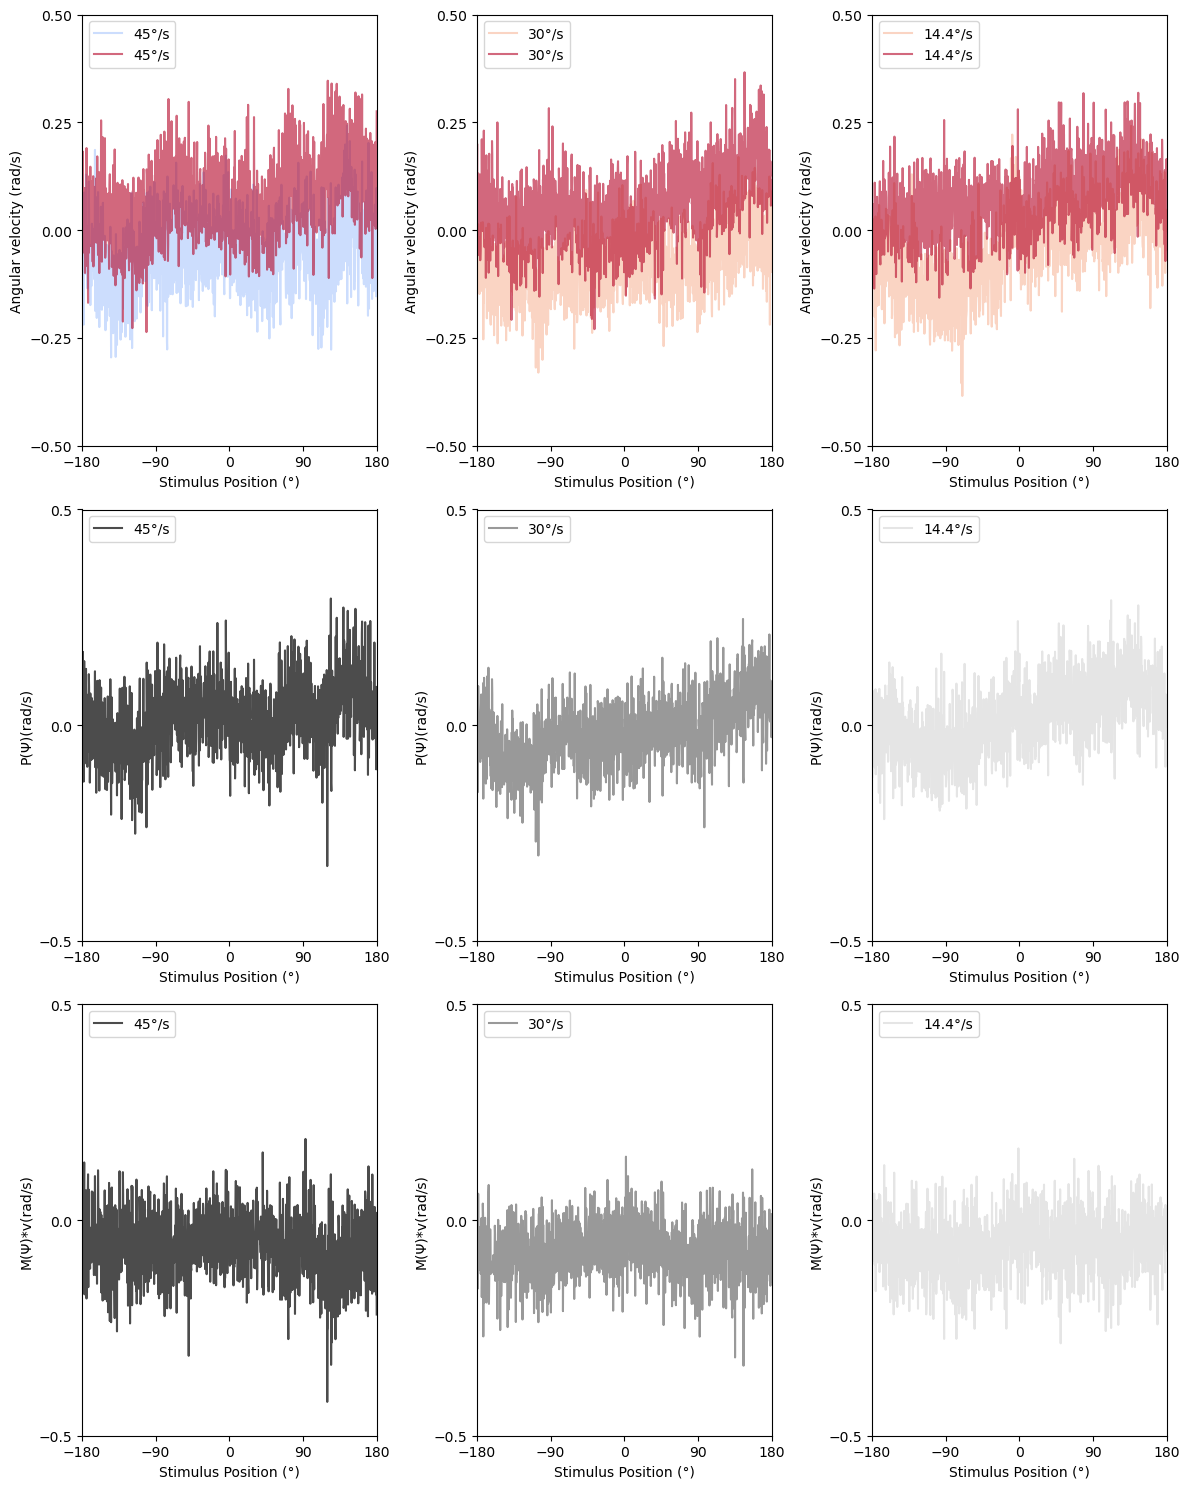

In [105]:
def adjust_unbalanced_arrays(arr1,arr2):
    if arr2.shape[0]>arr1.shape[0]:
        arr2 = arr2[np.random.choice(arr2.shape[0], size=arr1.shape[0])]
    elif arr1.shape[0]>arr2.shape[0]:
        arr1 = arr1[np.random.choice(arr1.shape[0], size=arr2.shape[0])]
    return arr1,arr2

randomly_adjust_unblanced_array=True
use_mean=True
colormap_name = "coolwarm"
sm = cm.ScalarMappable(cmap=colormap_name)
COL = MplColorHelper(colormap_name, 0, len(df["stim_type"].unique())/2+1)
y_axis_lim=[-0.5,0.5]
degree_sign = u'\N{DEGREE SIGN}'
fig2,((ax1,ax2,ax3),(ax4,ax5,ax6),(ax7,ax8,ax9)) = plt.subplots(
    nrows=3, ncols=3, figsize=(12, 15), tight_layout=True,
    #sharex=True,sharey='row'
)
cc_angle_dependant_arr1=np.vstack(cc_angle_dependant_list1)
cc_angle_dependant_arr2=np.vstack(cc_angle_dependant_list2)
cc_angle_dependant_arr3=np.vstack(cc_angle_dependant_list3)
c_angle_dependant_arr1=np.vstack(c_angle_dependant_list1)
c_angle_dependant_arr2=np.vstack(c_angle_dependant_list2)
c_angle_dependant_arr3=np.vstack(c_angle_dependant_list3)

if use_mean:
    cc_angle_value1=np.mean(cc_angle_dependant_arr1, axis=0)
    cc_angle_value2=np.mean(cc_angle_dependant_arr2, axis=0)
    cc_angle_value3=np.mean(cc_angle_dependant_arr3, axis=0)
    c_angle_value1=np.mean(c_angle_dependant_arr1, axis=0)
    c_angle_value2=np.mean(c_angle_dependant_arr2, axis=0)
    c_angle_value3=np.mean(c_angle_dependant_arr3, axis=0)
else:#use median
    cc_angle_value1=np.median(cc_angle_dependant_arr1, axis=0)
    cc_angle_value2=np.median(cc_angle_dependant_arr2, axis=0)
    cc_angle_value3=np.median(cc_angle_dependant_arr3, axis=0)
    c_angle_value1=np.median(c_angle_dependant_arr1, axis=0)
    c_angle_value2=np.median(c_angle_dependant_arr2, axis=0)
    c_angle_value3=np.median(c_angle_dependant_arr3, axis=0)
## quantify p and m system
if randomly_adjust_unblanced_array==True:
    c1,cc1=adjust_unbalanced_arrays(c_angle_dependant_arr1,cc_angle_dependant_arr1)
    c2,cc2=adjust_unbalanced_arrays(c_angle_dependant_arr2,cc_angle_dependant_arr2)
    c3,cc3=adjust_unbalanced_arrays(c_angle_dependant_arr3,cc_angle_dependant_arr3)
    if use_mean:
        p_values3=np.mean(c3+cc3, axis=0)/2
        p_values2=np.mean(c2+cc2, axis=0)/2
        p_values1=np.mean(c1+cc1, axis=0)/2
        m_values3=np.mean(cc3-c3, axis=0)/2
        m_values2=np.mean(cc2-c2, axis=0)/2
        m_values1=np.mean(cc1-c1, axis=0)/2
    else:
        p_values3=np.median(c3+cc3, axis=0)/2
        p_values2=np.median(c2+cc2, axis=0)/2
        p_values1=np.median(c1+cc1, axis=0)/2
        m_values3=np.median(cc3-c3, axis=0)/2
        m_values2=np.median(cc2-c2, axis=0)/2
        m_values1=np.median(cc1-c1, axis=0)/2
else:
    p_values3=(cc_angle_value3+c_angle_value3)/2
    p_values2=(cc_angle_value2+c_angle_value2)/2
    p_values1=(cc_angle_value1+c_angle_value1)/2
    m_values3=(cc_angle_value3-c_angle_value3)/2
    m_values2=(cc_angle_value2-c_angle_value2)/2
    m_values1=(cc_angle_value1-c_angle_value1)/2

ax1.plot(
    np.linspace(-180,180,cc_angle_dependant_arr1.shape[1]),
    cc_angle_value1,
    color=COL.get_rgb(1),
    alpha=0.6,
    label=f'45{degree_sign}/s'
)
ax1.plot(
    np.linspace(-180,180,c_angle_dependant_arr1.shape[1]),
    c_angle_value1,
    color=COL.get_rgb(6),
    alpha=0.6,
    label=f'45{degree_sign}/s'
)
ax2.plot(
    np.linspace(-180,180,cc_angle_dependant_arr2.shape[1]),
    cc_angle_value2,
    color=COL.get_rgb(2),
    alpha=0.6,
    label=f'30{degree_sign}/s'
)
ax2.plot(
    np.linspace(-180,180,c_angle_dependant_arr2.shape[1]),
    c_angle_value2,
    color=COL.get_rgb(5),
    alpha=0.6,
    label=f'30{degree_sign}/s'
)
ax3.plot(
    np.linspace(-180,180,cc_angle_dependant_arr3.shape[1]),
    cc_angle_value3,
    color=COL.get_rgb(2),
    alpha=0.6,
    label=f'14.4{degree_sign}/s'
)
ax3.plot(
    np.linspace(-180,180,c_angle_dependant_arr3.shape[1]),
    c_angle_value3,
    color=COL.get_rgb(5),
    alpha=0.6,
    label=f'14.4{degree_sign}/s'
)
ax1.set(
    yticks=[y_axis_lim[0],y_axis_lim[0]/2,0,y_axis_lim[1]/2,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="Angular velocity (rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax1.legend(loc="upper left")
ax2.set(
    yticks=[y_axis_lim[0],y_axis_lim[0]/2,0,y_axis_lim[1]/2,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="Angular velocity (rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax2.legend(loc="upper left")
ax3.set(
    yticks=[y_axis_lim[0],y_axis_lim[0]/2,0,y_axis_lim[1]/2,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="Angular velocity (rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax3.legend(loc="upper left")
ax4.plot(
    np.linspace(-180,180,cc_angle_dependant_arr1.shape[1]),
    p_values1,
    color='k',
    alpha=0.7,
    label=f'45{degree_sign}/s'
)
ax5.plot(
    np.linspace(-180,180,cc_angle_dependant_arr2.shape[1]),
    p_values2,
    color='k',
    alpha=0.4,
    label=f'30{degree_sign}/s'
)
ax6.plot(
    np.linspace(-180,180,cc_angle_dependant_arr3.shape[1]),
    p_values3,
    color='k',
    alpha=0.1,
    label=f'14.4{degree_sign}/s'
)
ax4.set(
    yticks=[y_axis_lim[0],0,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="P(Ψ)(rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax4.legend(loc="upper left")
ax5.set(
    yticks=[y_axis_lim[0],0,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="P(Ψ)(rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax5.legend(loc="upper left")
ax6.set(
    yticks=[y_axis_lim[0],0,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="P(Ψ)(rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax6.legend(loc="upper left")
ax7.plot(
    np.linspace(-180,180,cc_angle_dependant_arr1.shape[1]),
    m_values1,
    color='k',
    alpha=0.7,
    label=f'45{degree_sign}/s'
)
ax8.plot(
    np.linspace(-180,180,cc_angle_dependant_arr2.shape[1]),
    m_values2,
    color='k',
    alpha=0.4,
    label=f'30{degree_sign}/s'
)
ax9.plot(
    np.linspace(-180,180,cc_angle_dependant_arr3.shape[1]),
    m_values3,
    color='k',
    alpha=0.1,
    label=f'14.4{degree_sign}/s'
)
ax7.set(
    yticks=[y_axis_lim[0],0,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="M(Ψ)*v(rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax7.legend(loc="upper left")
ax8.set(
    yticks=[y_axis_lim[0],0,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="M(Ψ)*v(rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax8.legend(loc="upper left")
ax9.set(
    yticks=[y_axis_lim[0],0,y_axis_lim[1]],
    xticks=[-180,-90,0,90,180],
    ylim=[y_axis_lim[0],y_axis_lim[1]],
    xlim=[-180,180],
    ylabel="M(Ψ)*v(rad/s)",
    xlabel=f"Stimulus Position ({degree_sign})")
ax9.legend(loc="upper left")
file_name=f"angle_dependant_response.svg"
#fig2.savefig(file_name)

In [70]:
#if you want to wrap other matrix into pandas dataframe
c_name_list=column_name_list(output2_across_exp[0].shape[1],"angular_velocity_f")
tmp=pd.DataFrame(np.vstack(output2_across_exp),columns=c_name_list)
df_rest_index=df.reset_index(drop=True)
tmp=tmp.reset_index(drop=True)
df_combined=pd.concat([df_rest_index, tmp], axis=1)

In [ ]:
stim_type=df_combined["stim_type"].unique()
stim_type=np.sort(stim_type)
COL = MplColorHelper(colormap_name, 0, len(stim_type))
plotting_visual_guided_response(np.vstack(output1_across_exp),stim_type,df_combined,analysis_methods,10,COL)

In [ ]:
plotting_visual_guided_response(np.vstack(output2_across_exp),stim_type,df_combined,analysis_methods,10,COL)

#### Session 2.3: save the database

In [ ]:
## select trials whose post-stim ISI is 10 sec and save them as a matfile
trial_of_interest=df['preStim_ISI_duration']==10
those_index=np.where(trial_of_interest.values)[0]+1
if df.shape[0]==max(those_index):
    df_interest=df.iloc[those_index[:-1],:]
else:
    df_interest=df.iloc[those_index,:]
data_dict = {name: col.values for name, col in df_interest.items()}
summary_file_name = Path(this_dataset_dir) /"behavioural_summary_postISI_10s.mat"
savemat(summary_file_name, data_dict)

In [ ]:
## select trials whose post-stim ISI is 15 sec and save the rotation as a numpy file
df_rotation=np.concatenate(output2_across_exp)
trial_of_interest=df['preStim_ISI_duration']==15
those_index=np.where(trial_of_interest.values)[0]+1
summary_file_name = Path(this_dataset_dir) /"rotation_summary_postISI_15s.npy"
if df_rotation.shape[0]==max(those_index):
    np.save(summary_file_name,df_rotation[those_index[:-1],:])
else:
    np.save(summary_file_name,df_rotation[those_index,:])

In [ ]:
##if converting original pickle file to .mat file
from scipy.io import savemat
with open(r'Z:\DATA\experiment_trackball_Optomotor\MatrexVR\matrex_vr_coherence_database_yaw_vector.pickle', 'rb') as file:
    data = pd.read_pickle(file)
data_dict = {name: col.values for name, col in data.items()}
savemat(r'Z:\DATA\experiment_trackball_Optomotor\MatrexVR\matrex_vr_coherence_database.mat', data_dict)

In [71]:
# #file_name="matrex_vr_coherence_database_yaw_ori.pickle"
# file_name="matrex_vr_coherence_4hr_database_yaw_ori.pickle"
# df_combined.to_pickle(Path(this_dataset_dir)/file_name)
path_name = r'Z:\DATA\experiment_trackball_Optomotor\Zball\sweeping_conflict_database.parquet.gzip'
df_combined.to_parquet(path_name,compression='gzip')

In [ ]:
'''
df.to_csv(file_name)#file will be big when dataset is big
df.to_pickle(file_name)#easy to save
df.to_feather(file_name)#needs pyarrow and column names needs to be string
path_name = r'Z:\DATA\experiment_trackball_Optomotor\ANALYSIS\Sercan et al\density_database.parquet.gzip'
finished.to_parquet(path_name,compression='gzip')
finished=pd.read_parquet(path_name)
df.to_hdf(file_name, key='solitarious', mode='w')#better used in dataset that has certain structure
'''

#### Session 2.X: Analyse animal's behaviour with multi-engines

In [ ]:
##this cell start the multi-engines. Make sure to run only once
import time
import ipyparallel as ipp
def show_clusters():
    clusters = ipp.ClusterManager().load_clusters() 
    print("{:15} {:^10} {}".format("cluster_id", "state", "cluster_file")) 
    for c in clusters:
        cd = clusters[c].to_dict()
        cluster_id = cd['cluster']['cluster_id']
        controller_state = cd['controller']['state']['state']
        cluster_file = getattr(clusters[c], '_trait_values')['cluster_file']
        print("{:15} {:^10} {}".format(cluster_id, controller_state, cluster_file))
    return cluster_id

cluster = ipp.Cluster(n=6)
await cluster.start_cluster()
cluster_neuropc=show_clusters()

In [ ]:
cluster_neuropc=show_clusters()

In [ ]:
##input cluster_id from previous cell
rc = ipp.Client(cluster_id=cluster_neuropc)

# Create a DirectView for parallel execution
dview = rc.direct_view()

# Define a function for parallel processing
def process_directory(this_dir, analysis_methods):
    from analyse_stimulus_evoked_response import main
    # Check if the H5 file (curated dataset) exists
    summary,speed,rotation,travel_distance_whole_session=main(this_dir,analysis_methods)
    return (summary,speed,rotation,travel_distance_whole_session)

# Define analysis_methods

# Use parallel execution to process directories
results = dview.map_sync(process_directory, dir_list, [analysis_methods] * len(dir_list))

# Initialize result lists
summary_list=[]
output1_across_exp=[]
output2_across_exp=[]
output3_across_exp=[]
output4_across_exp=[]

# Collect and organize results
for result in results:
    if result is not None:
        summary,speed,rotation = result
        summary_list.append(summary)
        output1_across_exp.append(speed)
        output2_across_exp.append(rotation)
        output3_across_exp.append(travel_distance_whole_session)
        output4_across_exp.append(this_dir)

# Now, you have the results collected in the respective lists

In [ ]:
rc.shutdown()

#### Session 2.5: Load existing dataset

In [ ]:
#database_pattern = "matrexVR_coherence_database.pickle"
database_pattern = "matrex_vr_coherence_database_yaw_ori.pickle"
load_existing_dataset=True
this_database = find_file(this_dataset_dir, database_pattern)
velocity_pattern="velocity*.npy"
jaw_vector_pattern="*jaw_rotation.npy"
summary_pattern="behavioural*.pickle"
pattern_list=[velocity_pattern,jaw_vector_pattern,summary_pattern]
print(f"loading this {this_database}")
if this_database is None or this_database.is_file()==False:
    print("no post-analysis database created. Either run analysis cell to get the list of animal's response or assemble post-analysis dataset from individual animals")
    if len(summary_list)>0:
    #if 'summary_list' in locals():
        df=pd.DataFrame(pd.concat(summary_list))
        print("use local list created from jupyter notebook")
    else:
        velocity_list=[]
        summary_list=[]
        rotation_list=[]
        for this_pattern in pattern_list:
            for this_dir in dir_list:
                this_file = find_file(this_dir, this_pattern)
                if this_file.suffix==".npy":
                    print({f"npy file is found. Let's assemble them"})
                    if this_pattern==velocity_pattern:
                        velocity_list.append(np.load(this_file))
                    elif this_pattern==jaw_vector_pattern:
                        rotation_list.append(np.load(this_file))
                elif this_file.suffix==".pickle":
                    print({f"load individual animal's summary"})
                    summary_list.append(pd.read_pickle(this_file))
                else:
                    print({f"no particular file created in this path: {this_dir}. Skip this animal"})
                

        df_velocity=np.concatenate(velocity_list)
        df_rotation=np.concatenate(rotation_list)
        df=pd.DataFrame(pd.concat(summary_list,axis=0, ignore_index=True))
elif load_existing_dataset==True:
    df=pd.read_pickle(this_database)
    df.rename(columns = {'Unnamed: 0':'trial_number'}, inplace = True)
    print("load pickle into pandas dataframe")
else:
    print("do not know what to do here")

In [ ]:
def converting_follow_velocity(row):
    if row['stim_type'] <0:
        row['stim_type'] *= -1    # Check condition on the first column
        row.loc['angular_velocity_f0':] *= -1        # Modify the second column (columnA)
    return row

In [ ]:
df_filtered = df[~df['ID'].isin([3,7,15,16,19,35,38,65])]

In [ ]:
df_interest_no_lazy= df_filtered.apply(converting_follow_velocity, axis=1)
df_interest = df.apply(converting_follow_velocity, axis=1)

In [ ]:
#check the temperature at the onset of every experiment and plot the distribution
temperature_list=[]
num_trials=168
for i in range(int(df.shape[0]/num_trials)):
    temperature_list.append(df.iloc[i*num_trials]["temperature"])
plt.hist(temperature_list,bins=10)
plt.show()
#df_below35=df[df["ID"].isin(np.where(np.array(temperature_list)<35)[0])]
#df_above=df[df["ID"].isin(np.where(np.array(temperature_list)>35)[0])]

#### Session 3: plotting data

In [74]:
def plot_preview_summary(df,this_dataset_dir,analysis_methods,vr_no="all"):
    walk_threshold=200
    walk_threshold_tbt=1
    save_output= analysis_methods.get("save_output")
    visual_paradigm_name= analysis_methods.get("experiment_name")
    colormap = np.array(analysis_methods.get("graph_colour_code"))
    premature_turn=0.8#set this criteria to remove trials where animals starting to turn prior to the stimulus presentation
    fig, axes = plt.subplots(
        nrows=2, ncols=2, figsize=(18, 14), tight_layout=True
    )
    ax1, ax2, ax3, ax4 = axes.flatten()
    num_bins=10
    n, bins, patches = ax1.hist(df.groupby(['ID'])["travel_distance_isi"].sum().values,num_bins,color=colormap[3])
    ax1.set(
    ylabel="Count",
    xlabel="Walk distance (cm)")

    for id, entries in df.groupby(['ID']):
        if entries["travel_distance_isi"].sum()>walk_threshold:
            above_threshold=True
        else:
            above_threshold=False
        entries=entries[abs(entries["opto_index_isi"])<premature_turn]
        for idx, this_stim in entries.groupby("stim_type"):
            this_response=this_stim["opto_index"].values
            mean_response = np.mean(this_response, axis=0)
            sem_response = np.std(this_response, axis=0, ddof=1) / np.sqrt(
                this_response.shape[0]
            )
            if above_threshold == True:
                this_colour=colormap[5]
            else:
                this_colour=colormap[6]
            ax2.errorbar(
                idx,
                mean_response,
                yerr=sem_response,
                c=this_colour,
                fmt="o",
                elinewidth=2,
                capsize=3,
            )
    ax2.set_ylim(-1, 1)

    if visual_paradigm_name =="gratings":
        xlabel="Temporal frequency (Hz)"
    elif visual_paradigm_name =="coherence":
        xlabel="Coherence (%)"
    elif visual_paradigm_name =="sweeping":
        xlabel="type"
    ax2.set(
        yticks=[-1,0,1],
        ylabel="Optomotor Index",
        xlabel=xlabel)
        
    num_bins=200
    n, bins, patches = ax3.hist(df["travel_distance_isi"].values,num_bins,density=False,range=(0,40),color=colormap[3])
    ax3.set(
    ylabel="Density",
    xlabel="Walk distance (cm)"
    )
    for this_coherence,entries in df.groupby("stim_type"):
        #this_response = entries[(entries["travel_distance_isi"]>walk_threshold_tbt)&(abs(entries["opto_index_isi"])<premature_turn)]["opto_index"].values
        this_response = entries[entries["travel_distance_isi"]>walk_threshold_tbt]["opto_index"].values
        mean_response = np.mean(this_response, axis=0)
        sem_response = np.std(this_response, axis=0, ddof=1) / np.sqrt(this_response.shape[0])
        ax4.errorbar(
            this_coherence,
            mean_response,
            yerr=sem_response,
            c=colormap[0],
            fmt="o",
            elinewidth=2,
            capsize=3,
        )
        plot_scatter_violin(this_response,this_coherence)
    ax4.set_ylim(-1, 1)
    ax4.set(
        yticks=[-1,-0.5,0,0.5,1],
        ylabel="Optomotor Index",
        xlabel=xlabel)
    fig.suptitle(f'The response of locusts during {visual_paradigm_name} stimulus presentation')
    ax1.title.set_text('The total walk distance of every locust')
    ax2.title.set_text('The optomotor index of every locust')
    ax3.title.set_text('The walk distance of every trial')
    ax4.title.set_text('The optomotor index of every walk trial')
    fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_summary.svg"
    if save_output==True:
        fig.savefig(Path(this_dataset_dir)/fig_name)

In [ ]:
plot_preview_summary(df_combined,this_dataset_dir,analysis_methods)

In [ ]:
#define the first and last frames to analyse
stim_duration=analysis_methods.get("stim_duration")
interval_duration=analysis_methods.get("interval_duration")
if type(interval_duration) == list and type(stim_duration) == list:
    analysis_window = [
        min(interval_duration) * -1,
        max(stim_duration) + min(interval_duration),
    ]
elif type(interval_duration) == list:
    analysis_window = [
        min(interval_duration) * -1,
        stim_duration + min(interval_duration),
    ]
elif type(stim_duration) == list:
    analysis_window = [
        interval_duration * -1,
        max(stim_duration) + interval_duration,
    ]
else:
    analysis_window = [
        interval_duration * -1,
        stim_duration + interval_duration,
    ]
init_frame=analysis_methods.get("camera_fps")*abs(analysis_window[0])
end_frame=analysis_methods.get("camera_fps")*analysis_window[1]
print(init_frame,end_frame)

In [ ]:
def plot_yaw_angular_velocity(df,analysis_methods,init_frame=1000,end_frame=3500,vr_no="all",colormap_name="coolwarm"):
    save_output= analysis_methods.get("save_output",False)
    visual_paradigm_name= analysis_methods.get("experiment_name")
    camera_fps=analysis_methods.get("camera_fps")
    active_trial_only=analysis_methods.get("active_trial_only",False)
    COL = MplColorHelper(colormap_name, 0, len(df["stim_type"].unique())-1)
    sm = cm.ScalarMappable(cmap=colormap_name)
    using_bs_ci=False
    use_mean=True
    stimulus_velocity=64 #unit degree/s
    walk_threshold_tbt=1
    premature_turn=0.8#set this criteria to remove animals starting to make turn turing ISI
    fig, axes = plt.subplots(
        nrows=1, ncols=2, figsize=(12, 10))
    ax1, ax2, = axes.flatten()

    fig_1by1, subplots = plt.subplots(
        nrows=1, ncols=len(df["stim_type"].unique())+1, figsize=(20, 4), tight_layout=True
    )
    if active_trial_only==True:
        df_selected=df[(df['travel_distance_isi']>walk_threshold_tbt) & (abs(df["opto_index_isi"])<premature_turn)]
    else:
        df_selected=df
    i=0
    for this_stim, entries in df_selected.groupby('stim_type'):
        dif_data=entries.loc[:,'angular_velocity_f0':].values
        #dif_data=np.diff(data,axis=1)
        data=np.cumsum(dif_data,axis=1)
        time_points = np.arange(data.shape[1])
        time_points_b = np.tile(time_points, (data.shape[0], 1))
        #define the stimulus speed in the first iteration
        if i ==0:
            xticks = [0, init_frame, end_frame]
            xticklabels = [str(analysis_window[0]), "0", str(stim_duration)]
            y_range=150
            tmp = np.full(data.shape[1],np.nan)
            dif_tmp= np.full(dif_data.shape[1],np.nan)
            stim_w_array=np.ones(end_frame-init_frame)*stimulus_velocity*np.pi/180
            tmp[init_frame:end_frame]=np.cumsum(stim_w_array)
            dif_tmp[init_frame:end_frame]=stim_w_array
        #ax1.plot(time_points_b, data, linestyle='-',linewidth=0.1,color=COL.get_rgb(i))

        #plot trial-by-trial response
        ax1.scatter(time_points_b, data, s=0.01,alpha=0.1,color=COL.get_rgb(i))
        subplots[i].scatter(time_points_b, data, s=0.01,alpha=0.1,color=COL.get_rgb(i))
        subplots[i].plot(time_points,tmp,color='k',linewidth=0.8)
        subplots[i].plot(time_points,tmp*-1,color='k',linewidth=0.8)
        subplots[i].axvline(
        x=init_frame,
        color="black",
        linestyle="--",
        label="Stimulus Starts",
        )
        subplots[i].axvline(
            x=end_frame,
            color="black",
            linestyle="--",
            label="Stimulus Ends",
        )
        subplots[i].set(
        ylabel="Orientation (rad)",
        yticks=[-y_range,0,y_range],
        ylim=[-y_range,y_range],
        xticks=xticks,
        xticklabels=xticklabels,
        xlabel="Time (s)",
    )
        #plot average response
        if use_mean==True:
            m_data = np.mean(data, axis=0)
            m_dif_data = np.mean(dif_data, axis=0)
        else:
            m_data=np.median(data, axis=0)
            m_dif_data=np.median(dif_data, axis=0)
        #ax2.plot(time_points,median_response,color=COL.get_rgb(i))
        ax2.plot(time_points[1:],m_dif_data,color=COL.get_rgb(i))
        subplots[len(df["stim_type"].unique())].plot(time_points,m_data,color=COL.get_rgb(i))

        ##to plot distribution with bootstrap 95% confidence interval
        y1,y2=get_fill_between_range(data,False,True)
        dif_y1,dif_y2=get_fill_between_range(dif_data,True,False)
        # if using_bs_ci:
        #     # data=(this_w,)
        #     # res=st.bootstrap(data,np.std,n_resamples=99,vectorized=True,random_state=1)
        #     # y1=res.confidence_interval[0]
        #     # y2=res.confidence_interval[1]
        #     # del data
        #     # data=(this_dif_w,)
        #     # res=st.bootstrap(data,np.std,n_resamples=99,vectorized=True,random_state=1)
        #     # dif_y1=res.confidence_interval[0]
        #     # dif_y2=res.confidence_interval[1]
        #     confidence_level = 0.95
        #     ##to plot distribution with 95% confidence interval with normal distribution
        #     st.t.interval(alpha=0.95, df=len(data)-1, loc=np.mean(data), scale=st.sem(data))
        #     cl95=st.norm.interval(confidence_level,loc=Ws,scale=st.sem(this_w))
        #     y1=cl95[0][:]
        #     y2=cl95[1][:]
        #     cl95=st.norm.interval(confidence_level,loc=m_dif_data,scale=st.sem(this_dif_w))
        #     dif_y1=cl95[0][:]
        #     dif_y2=cl95[1][:]

        # else:
        #     ##to plot distribution with sem
        #     sem_response = np.std(this_w, axis=0, ddof=1) / np.sqrt(this_w.shape[0])
        #     y1 = Ws + sem_response
        #     y2 = Ws - sem_response
        #     sem_response = np.std(this_dif_w, axis=0, ddof=1) / np.sqrt(this_dif_w.shape[0])
        #     dif_y1=m_dif_data + sem_response
        #     dif_y2=m_dif_data - sem_response
        # #ax2.fill_between(time_points,y1,y2, alpha=0.5,color=COL.get_rgb(i))
        ax2.fill_between(time_points[1:],dif_y1,dif_y2, alpha=0.5,color=COL.get_rgb(i))
        subplots[len(df["stim_type"].unique())].fill_between(time_points,y1,y2, alpha=0.5,color=COL.get_rgb(i))
        i=i+1

    ax1.plot(time_points,tmp,color='k',linewidth=0.8)
    ax1.plot(time_points,tmp*-1,color='k',linewidth=0.8)
    ax2.plot(time_points[1:],dif_tmp,color='k',linewidth=0.8)
    ax2.plot(time_points[1:],dif_tmp*-1,color='k',linewidth=0.8)
    subplots[len(df["stim_type"].unique())].plot(time_points,tmp,color='k',linewidth=0.8)
    subplots[len(df["stim_type"].unique())].plot(time_points,tmp*-1,color='k',linewidth=0.8)
    ax1.axvline(
        x=init_frame,
        color="black",
        linestyle="--",
        label="Stimulus Starts",
    )
    ax1.axvline(
        x=end_frame,
        color="black",
        linestyle="--",
        label="Stimulus Ends",
    )
    ax2.axvline(
        x=init_frame,
        color="black",
        linestyle="--",
        label="Stimulus Starts",
    )
    ax2.axvline(
        x=end_frame,
        color="black",
        linestyle="--",
        label="Stimulus Ends",
    )
    subplots[len(df["stim_type"].unique())].axvline(
        x=init_frame,
        color="black",
        linestyle="--",
        label="Stimulus Starts",
    )
    subplots[len(df["stim_type"].unique())].axvline(
        x=end_frame,
        color="black",
        linestyle="--",
        label="Stimulus Ends",
    )
    ax1.set(
        ylabel="Orientation (rad)",
        yticks=[-y_range,0,y_range],
        ylim=[-y_range,y_range],
        xticks=xticks,
        xticklabels=xticklabels,
        xlabel="Time (s)",
    )
    ax2.set(
        ylabel="Angular velocity (rad/s)",
        xticks=xticks,
        yticks=[-1,0,1],
        #ylim=[-0.005,0.02],
        ylim=[-2.5,2.5],
        xticklabels=xticklabels,
        xlabel="Time (s)",
    )
    subplots[len(df["stim_type"].unique())].set(
        xticks=xticks,
        yticks=[-20,0,20],
        xticklabels=xticklabels,
        xlabel="Time (s)",
    )
    tick_positions = np.linspace(0, 1, len(df["stim_type"].unique()))
    these_coherence=df["stim_type"].unique()
    these_coherence.sort()
    tick_labels = [str(value) for value in these_coherence]
    cbar = plt.colorbar(sm, ax=[ax1,ax2], orientation="horizontal", location='top',ticks=tick_positions,aspect=80)
    cbar.set_ticklabels(tick_labels)

    if save_output==True:
        fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_orientation_dynamics.png"
        fig.savefig(Path(this_dataset_dir)/fig_name)
        fig_name=f"{vr_no}_bonfic_{visual_paradigm_name}_orientation_dynamics_tbt.png"
        fig_1by1.savefig(Path(this_dataset_dir)/fig_name)

In [ ]:
colormap_name = "viridis"
plot_yaw_angular_velocity(df_interest,analysis_methods,init_frame,end_frame,"all",colormap_name)
#plot_yaw_angular_velocity(df_15,analysis_methods,init_frame,end_frame,"all",colormap_name)
#plot_yaw_angular_velocity(df_active_15,analysis_methods,init_frame,end_frame,"all",colormap_name)
# plot_yaw_angular_velocity(df_10,analysis_methods)
# plot_yaw_angular_velocity(df_active_10,analysis_methods)

In [ ]:
vr_groups = df.groupby('VR_no')
for vr_no, entries in vr_groups:
    plot_preview_summary(entries,this_dataset_dir,analysis_methods,vr_no)